In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori,association_rules

In [16]:
data=pd.read_csv("Retail_Transaction_Dataset.csv")
data.head(5)
print(data.columns)

Index(['CustomerID', 'ProductID', 'Quantity', 'Price', 'TransactionDate',
       'PaymentMethod', 'StoreLocation', 'ProductCategory',
       'DiscountApplied(%)', 'TotalAmount'],
      dtype='object')


In [29]:
transaction_col='CustomerID'
item_col='ProductCategory'

data=data.dropna(subset=['CustomerID','ProductCategory'])

data[transaction_col]=data[transaction_col].astype(str).str.strip()
data[item_col]=data[item_col].astype(str).str.strip()

In [30]:
transaction=data.groupby(transaction_col)[item_col].apply(list).tolist()

transaction[:5]

[['Books'], ['Books'], ['Electronics'], ['Home Decor'], ['Books']]

In [31]:
te=TransactionEncoder()

encoded_data=te.fit(transaction).transform(transaction)

df=pd.DataFrame(encoded_data,columns=te.columns_)

df.head(5)

,Books,Clothing,Electronics,Home Decor
0,True,False,False,False
1,True,False,False,False
2,False,False,True,False
3,False,False,False,True
4,True,False,False,False


In [32]:
frequent_item=apriori(df,min_support=0.001,use_colnames=True)

print(frequent_item)

    support                   itemsets
0  0.260012                    (Books)
1  0.259791                 (Clothing)
2  0.259192              (Electronics)
3  0.258762               (Home Decor)
4  0.006449          (Books, Clothing)
5  0.006428       (Electronics, Books)
6  0.006438        (Books, Home Decor)
7  0.006375    (Electronics, Clothing)
8  0.006186     (Home Decor, Clothing)
9  0.006480  (Electronics, Home Decor)


In [33]:
rules=association_rules(frequent_item,metric="confidence",min_threshold=0.01)

print(rules)

      antecedents    consequents  antecedent support  consequent support  \
0         (Books)     (Clothing)            0.260012            0.259791   
1      (Clothing)        (Books)            0.259791            0.260012   
2   (Electronics)        (Books)            0.259192            0.260012   
3         (Books)  (Electronics)            0.260012            0.259192   
4         (Books)   (Home Decor)            0.260012            0.258762   
5    (Home Decor)        (Books)            0.258762            0.260012   
6   (Electronics)     (Clothing)            0.259192            0.259791   
7      (Clothing)  (Electronics)            0.259791            0.259192   
8      (Clothing)   (Home Decor)            0.259791            0.258762   
9    (Home Decor)     (Clothing)            0.258762            0.259791   
10  (Electronics)   (Home Decor)            0.259192            0.258762   
11   (Home Decor)  (Electronics)            0.258762            0.259192   

     suppor

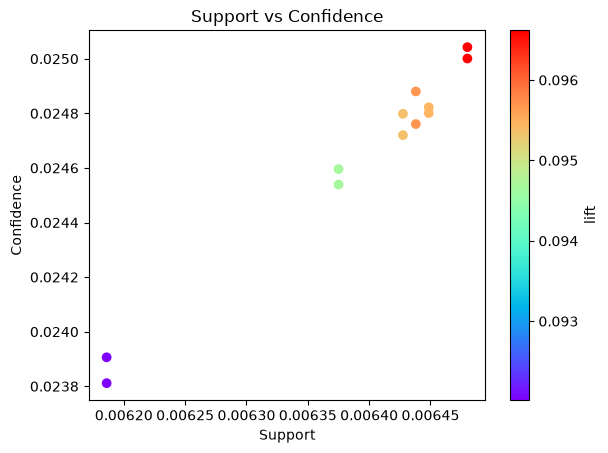

In [37]:
# visualization

plt.scatter(rules['support'],rules['confidence'],c=rules['lift'],cmap="rainbow")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Support vs Confidence")
plt.colorbar(label='lift')
plt.show()

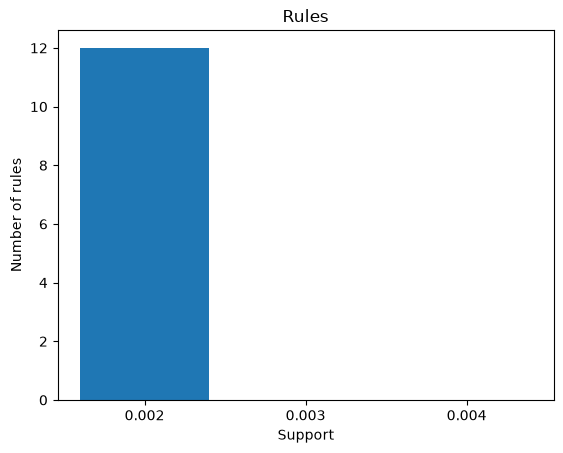

In [40]:
support_values=[0.003,0.01,0.015]
counts=[]

for val in support_values:
    count=(rules['support']>=val).sum()
    counts.append(count)

plt.bar(['0.002','0.003','0.004'],counts)
plt.xlabel("Support")
plt.ylabel("Number of rules")
plt.title("Rules")
plt.show()